# Práctica 9.- Mejorar calidad de imagen a color

## Universidad Autónoma de Nuevo León
## Facultad de Ingeniería Mecánica y Eléctrica

Integrantes:
- Cristian Alexis De La Cruz Cabrera 2065212
- Octavio Rodríguez Cázares 2100243

Grupo: 309
Hora: N4 / Día: Miércoles

Docence : Ing. Noe Adiel Ponce Moreno


Selecciona los archivos que faltan:
- Im004_ACRIMA.jpg
- imagen 2.jpg
- imagen 1.jpg


Saving Im004_ACRIMA.jpg to Im004_ACRIMA.jpg
Saving imagen 2.jpg to imagen 2.jpg
Saving Imagen 1.jpg to Imagen 1.jpg


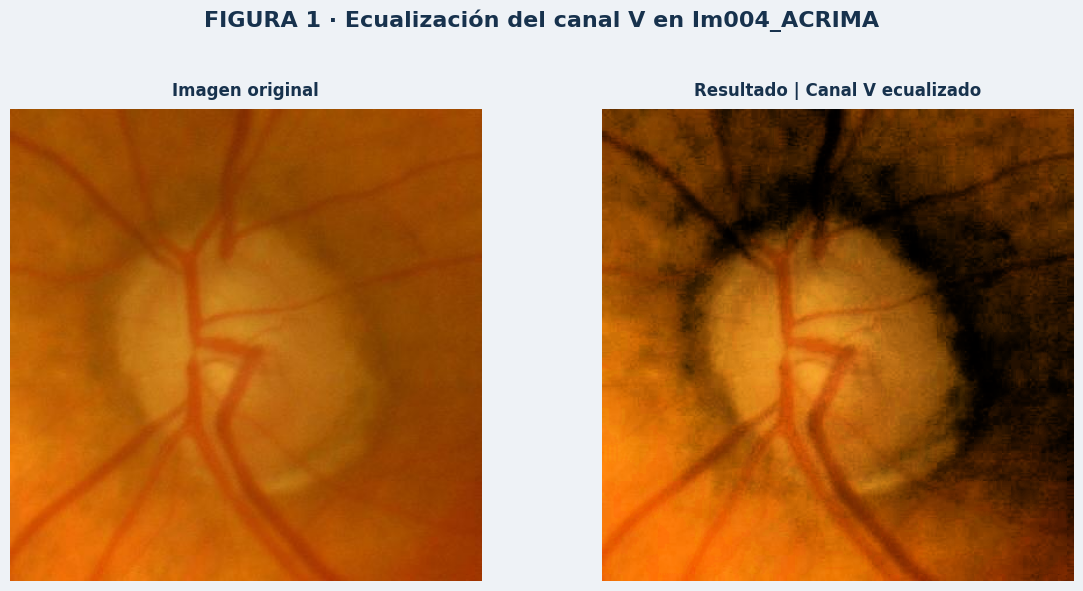

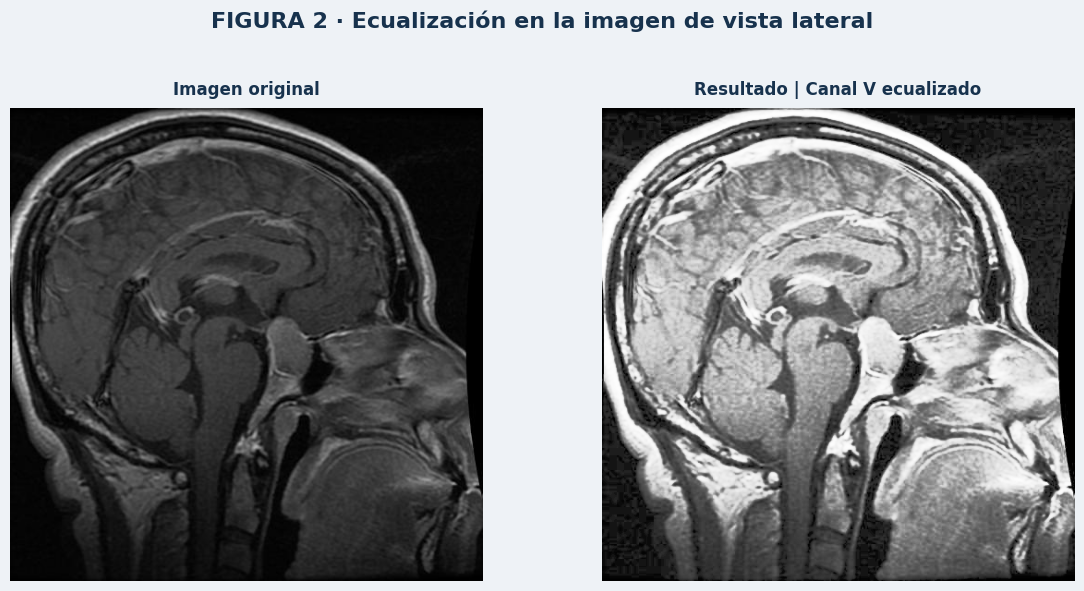

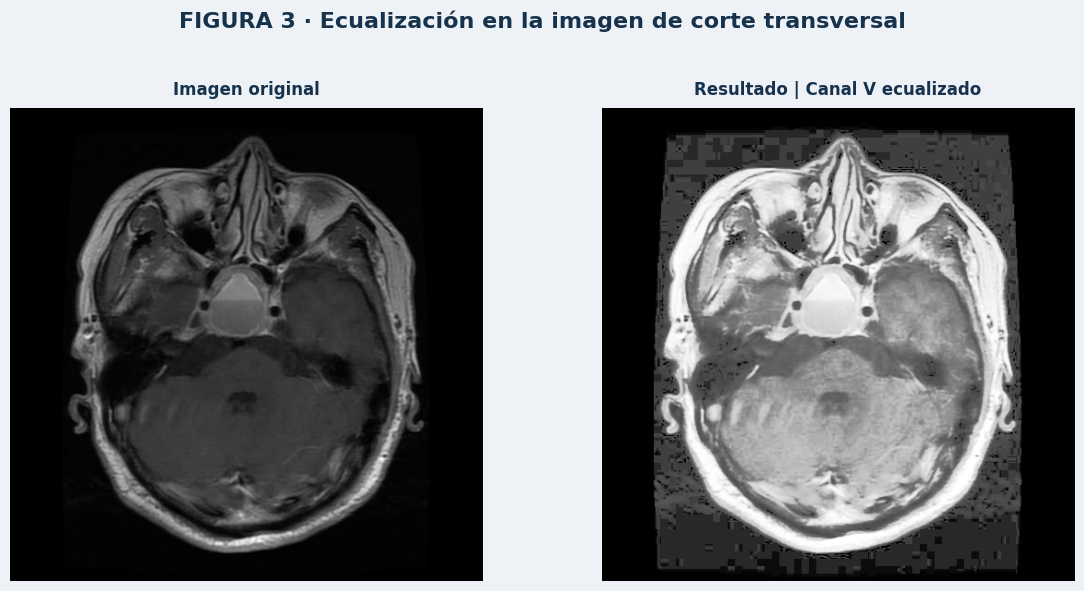

Procesamiento terminado.
Se generaron las tres figuras:
1. Im004_ACRIMA.
2. Imagen de vista lateral.
3. Imagen de corte transversal.

Las comparaciones y las imágenes procesadas se guardaron en la carpeta resultados_practica_9.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import files



ejercicios = [
    {
        "archivo": "Im004_ACRIMA.jpg",
        "titulo": "Ecualización del canal V en Im004_ACRIMA"
    },
    {
        "archivo": "imagen 2.jpg",
        "titulo": "Ecualización en la imagen de vista lateral"
    },
    {
        "archivo": "imagen 1.jpg",
        "titulo": "Ecualización en la imagen de corte transversal"
    }
]

carpeta_resultados = Path("resultados_practica_9")
carpeta_resultados.mkdir(exist_ok=True)


# 2. PRESENTACIÓN DE LAS FIGURAS

plt.rcParams.update({
    "figure.facecolor": "#eef2f6",
    "axes.facecolor": "#eef2f6",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 12
})


# 3. BUSCAR LOS ARCHIVOS CARGADOS


def buscar_archivo(nombre):

    for archivo in Path(".").iterdir():

        if archivo.is_file():
            if archivo.name.lower() == nombre.lower():
                return archivo

    return None


faltantes = [
    ejercicio["archivo"]
    for ejercicio in ejercicios
    if buscar_archivo(ejercicio["archivo"]) is None
]

if faltantes:

    print("Selecciona los archivos que faltan:")

    for nombre in faltantes:
        print("-", nombre)

    archivos_subidos = files.upload()


faltantes = [
    ejercicio["archivo"]
    for ejercicio in ejercicios
    if buscar_archivo(ejercicio["archivo"]) is None
]

if faltantes:
    raise FileNotFoundError(
        "No se encontraron estos archivos: "
        + ", ".join(faltantes)
        + ". Revisa sus nombres y vuelve a ejecutar la celda."
    )


# 4. FUNCIÓN PARA ECUALIZAR EL CANAL V


def ecualizar_canal_v(nombre_archivo):

    ruta = buscar_archivo(nombre_archivo)

    # Cargar la imagen a color en formato BGR
    img_bgr = cv2.imread(
        str(ruta),
        cv2.IMREAD_COLOR
    )

    if img_bgr is None:
        raise ValueError(
            f"No se pudo leer la imagen: {nombre_archivo}"
        )

    # Convertir de BGR a HSV
    img_hsv = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2HSV
    )

    # Separar los canales
    h, s, v = cv2.split(img_hsv)

    # Ecualizar solamente el canal V
    v_eq = cv2.equalizeHist(v)

    # Reconstruir HSV conservando H y S
    img_hsv_eq = cv2.merge([
        h,
        s,
        v_eq
    ])

    # Regresar a BGR
    img_eq_bgr = cv2.cvtColor(
        img_hsv_eq,
        cv2.COLOR_HSV2BGR
    )

    # Convertir ambas imágenes a RGB para mostrarlas
    img_rgb = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2RGB
    )

    img_eq_rgb = cv2.cvtColor(
        img_eq_bgr,
        cv2.COLOR_BGR2RGB
    )

    return {
        "original_rgb": img_rgb,
        "resultado_rgb": img_eq_rgb,
        "resultado_bgr": img_eq_bgr,
        "v_original": v,
        "v_ecualizado": v_eq
    }


# 5. PROCESAR LAS TRES IMÁGENES


resultados = {}

for numero, ejercicio in enumerate(ejercicios, start=1):

    nombre_archivo = ejercicio["archivo"]
    titulo = ejercicio["titulo"]

    datos = ecualizar_canal_v(nombre_archivo)

    # Guardar los resultados en una variable
    resultados[nombre_archivo] = datos

    # Crear una figura para este ejercicio
    fig, ejes = plt.subplots(
        1,
        2,
        figsize=(12, 6)
    )

    fig.suptitle(
        f"FIGURA {numero} · {titulo}",
        fontsize=16,
        fontweight="bold",
        color="#17324d",
        y=0.98
    )

    # Imagen original
    ejes[0].imshow(datos["original_rgb"])

    ejes[0].set_title(
        "Imagen original",
        fontweight="bold",
        color="#17324d",
        pad=10
    )

    ejes[0].axis("off")

    # Imagen procesada
    ejes[1].imshow(datos["resultado_rgb"])

    ejes[1].set_title(
        "Resultado | Canal V ecualizado",
        fontweight="bold",
        color="#17324d",
        pad=10
    )

    ejes[1].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.92])

    nombre_figura = (
        carpeta_resultados
        / f"Figura_{numero}_comparacion.png"
    )

    fig.savefig(
        nombre_figura,
        dpi=180,
        bbox_inches="tight"
    )

    nombre_resultado = (
        carpeta_resultados
        / f"{Path(nombre_archivo).stem}_ecualizada.png"
    )

    cv2.imwrite(
        str(nombre_resultado),
        datos["resultado_bgr"]
    )


    plt.show()
    plt.close(fig)


print("Procesamiento terminado.")
print("Se generaron las tres figuras:")
print("1. Im004_ACRIMA.")
print("2. Imagen de vista lateral.")
print("3. Imagen de corte transversal.")

print(
    "\nLas comparaciones y las imágenes procesadas "
    "se guardaron en la carpeta resultados_practica_9."
)